# CRAPome filtering — effect on disease modules

Companion to `pipeline_results_analysis.ipynb` (the GTEx / PaxDB / TCGA *expression* filtering
analysis), but for **CRAPome contaminant filtering**. CRAPome removes edges/nodes that are
frequent AP-MS background binders (Mellacheruvu et al., Nat Methods 2013) rather than genes that
are unexpressed in a tissue — so it is not tissue-specific and has no `context` (tissue) axis.

Three structural differences from the expression-filtering notebook, all of which change the
analysis design:

* **One run directory holds every disease.** All four diseases (`alzheimers`, `diabetes_typeI`,
  `diabetes_typeII`, `LUAD`) were run together in `data/results/crapome_validation_run`, so the
  disease label is recovered from the seed-file prefix (`alzheimers_symbol_seeds` → `alzheimers`),
  not from the folder name as in the expression notebook.
* **No `context` token in the ids.** A filtered module id is
  `<seeds>.<network>.<organism>.<id_space>.CRAPome.<threshold>.<amim>` (contrast the expression
  ids, which insert a tissue `<context>` before the source). `parse_run_id()` below is adapted
  accordingly.
* **A single source (`CRAPome`) at a single threshold (`0.5`).** There is no threshold sweep to
  plot, so every figure here is a **paired baseline-vs-filtered comparison** instead of the
  expression notebook's threshold lines.

Covered, per the three questions asked: **robustness** (seed-perturbation stability +
rediscovery), **module similarity** (how much filtering rewrites each module, and how the modules
cluster), and **biological relevance** (g:Profiler pathway correspondence + disease-specific
pathway significance). Outputs go to `results_analysis_output/crapome/`.

In [1]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(RColorBrewer)
  library(patchwork)
  library(pheatmap)
})

REPO_ROOT      <- normalizePath("/nfs/home/students/m.tan/BA")
RESULTS_FOLDER <- file.path(REPO_ROOT, "data", "results")
CRAPOME_RUN    <- file.path(RESULTS_FOLDER, "crapome_validation_run")
CRAPOME_OUTDIR <- file.path(REPO_ROOT, "results_analysis_output", "crapome")
dir.create(CRAPOME_OUTDIR, recursive = TRUE, showWarnings = FALSE)

# "network" is the leading token of the id (string/iid), followed by organism + id_space, e.g.
# "string.human_links_v12_0_min900.Symbol" or "iid.human.Symbol" (confirmed against the mqc
# summary tables directly). CRAPome is the only source and 0.5 the only threshold in this run,
# but the parser is written generically so more thresholds/sources would still parse.
KNOWN_NETWORKS <- c("string", "iid")
KNOWN_SOURCES  <- c("CRAPome")
KNOWN_AMIMS    <- c("robust_bias_aware", "robust", "domino", "diamond", "firstneighbor", "rwr")

AMIM_LABELS <- c(
  domino = "DOMINO", robust = "ROBUST", robust_bias_aware = "ROBUST (bias-aware)",
  diamond = "DIAMOnD", rwr = "RWR", firstneighbor = "1st Neighbors"
)
NETWORK_LABELS <- c(string = "STRING", iid = "IID")

# all four diseases live in one run dir here, so disease is recovered from the seed-file prefix
# rather than from the folder name (as the expression notebook does)
DISEASE_FROM_SEEDS <- c(
  alzheimers_symbol_seeds      = "alzheimers",
  diabetes_typeI_symbol_seeds  = "diabetes_typeI",
  diabetes_typeII_symbol_seeds = "diabetes_typeII",
  luad_symbol_seeds            = "LUAD"
)
DISEASE_ORDER  <- c("alzheimers", "diabetes_typeI", "diabetes_typeII", "LUAD")
DISEASE_LABELS <- c(
  alzheimers = "Alzheimer's", diabetes_typeI = "Type I diabetes",
  diabetes_typeII = "Type II diabetes", LUAD = "LUAD"
)

# baseline (unfiltered) vs. CRAPome-filtered — the only two configurations in this run
CONFIG_LEVELS <- c("Unfiltered", "CRAPome")
CONFIG_COLORS <- c(Unfiltered = "grey60", CRAPome = "#1b9e77")

# meta.id = "<seeds>.<network>.<organism>.<id_space>.CRAPome.<threshold>.<amim>" (filtered) or
# "<seeds>.<network>.<organism>.<id_space>.<amim>" (unfiltered baseline). No <context> token,
# unlike the expression notebook. Threshold can contain a dot ("0.5") so it is the trailing
# catch-all group. robust_bias_aware precedes robust in the alternation so the longer name wins.
filtered_pattern <- sprintf(
  "^(.+)\\.(%s)\\.[^.]+\\.[^.]+\\.(%s)\\.(.+)\\.(%s)$",
  paste(KNOWN_NETWORKS, collapse = "|"),
  paste(KNOWN_SOURCES, collapse = "|"),
  paste(KNOWN_AMIMS, collapse = "|")
)
baseline_pattern <- sprintf(
  "^(.+)\\.(%s)\\.[^.]+\\.[^.]+\\.(%s)$",
  paste(KNOWN_NETWORKS, collapse = "|"),
  paste(KNOWN_AMIMS, collapse = "|")
)

parse_run_id <- function(id) {
  mf <- str_match(id, filtered_pattern)  # 1 full, 2 seeds, 3 net, 4 source, 5 threshold, 6 amim
  mb <- str_match(id, baseline_pattern)  # 1 full, 2 seeds, 3 net, 4 amim
  is_filtered <- !is.na(mf[, 1])
  tibble(
    seeds_id  = if_else(is_filtered, mf[, 2], mb[, 2]),
    network   = if_else(is_filtered, mf[, 3], mb[, 3]),
    source    = mf[, 4],
    threshold = mf[, 5],
    amim      = if_else(is_filtered, mf[, 6], mb[, 4]),
    filtered  = is_filtered
  )
}

# attaches parsed fields + disease to a raw table whose id column is `id_col`; drops rows that
# aren't real AMIM modules (amim == "no_tool" and anything that failed to parse)
attach_meta <- function(raw, id_col) {
  parsed <- parse_run_id(raw[[id_col]])
  bind_cols(raw, parsed) %>%
    mutate(
      disease   = unname(DISEASE_FROM_SEEDS[seeds_id]),
      threshold = as.numeric(threshold),
      config    = factor(if_else(filtered, "CRAPome", "Unfiltered"), levels = CONFIG_LEVELS)
    ) %>%
    filter(!is.na(amim), !is.na(disease))
}

# factor helpers so every figure orders diseases/networks/methods the same way
fct_disease <- function(x) factor(DISEASE_LABELS[x], levels = DISEASE_LABELS[DISEASE_ORDER])
fct_network <- function(x) factor(NETWORK_LABELS[x], levels = NETWORK_LABELS[KNOWN_NETWORKS])
fct_amim    <- function(x) factor(AMIM_LABELS[x],    levels = AMIM_LABELS[KNOWN_AMIMS])

## What the filter removed

Quick orientation before the module-level analysis: the pipeline's own
`mqc_summaries/crapome_filtering_statistics_mqc.tsv` records, per base network, how many nodes
were flagged as CRAPome contaminants and how many were actually dropped at this threshold. Only
a small fraction of flagged nodes cross the removal threshold, so CRAPome filtering is a much
lighter touch than expression filtering — useful context for why the module-level effects below
are comparatively small.

In [2]:
crapome_stats <- read_tsv(
  file.path(CRAPOME_RUN, "mqc_summaries", "crapome_filtering_statistics_mqc.tsv"),
  show_col_types = FALSE
)
crapome_stats %>%
  transmute(
    network,
    flagged_as_crapome   = nodes_marked_as_crapome_absolute,
    flagged_fraction     = round(nodes_marked_as_crapome_relative, 3),
    removed_by_threshold = genes_filtered_by_threshold_absolute,
    removed_fraction     = round(genes_filtered_by_threshold_relative, 4)
  )

network,flagged_as_crapome,flagged_fraction,removed_by_threshold,removed_fraction
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
iid.human.Symbol.CRAPome.0.5,7067,0.386,96,0.0052
string.human_links_v12_0_min900.Symbol.CRAPome.0.5,5423,0.455,82,0.0069


# 1. Robustness (seed perturbation)

Source: `mqc_summaries/seed_perturbation_mqc.tsv` (one row per
`<seeds>.<network>.<id>.<amim>` combination, filtered or baseline), produced by
`SEEDPERTURBATIONEVALUATION`. Three metrics:

* `avg_jaccard_index` — module stability under seed perturbation (higher = more robust),
* `rediscovery_rate` — how well held-out seeds are recovered,
* `normalized_rediscovery_rate` — the same, size-normalized.

Because there is a single filtered configuration, each metric is shown as a **paired
baseline-vs-CRAPome bar chart** (network rows × method columns, one bar pair per disease) and as
a **delta heatmap** (`CRAPome − baseline`; blue = filtering helps, red = filtering hurts).

In [3]:
ROB_METRICS <- c(
  avg_jaccard_index           = "Robustness (avg. Jaccard index)",
  rediscovery_rate            = "Seed rediscovery rate",
  normalized_rediscovery_rate = "Normalized seed rediscovery rate"
)

robustness <- attach_meta(
  read_tsv(file.path(CRAPOME_RUN, "mqc_summaries", "seed_perturbation_mqc.tsv"), show_col_types = FALSE),
  "id"
)

ROBUSTNESS_OUTDIR <- file.path(CRAPOME_OUTDIR, "robustness")
dir.create(ROBUSTNESS_OUTDIR, recursive = TRUE, showWarnings = FALSE)

dplyr::count(robustness, disease, network, config)

disease,network,config,n
<chr>,<chr>,<fct>,<int>
LUAD,iid,Unfiltered,6
LUAD,iid,CRAPome,6
LUAD,string,Unfiltered,6
LUAD,string,CRAPome,6
alzheimers,iid,Unfiltered,6
alzheimers,iid,CRAPome,6
alzheimers,string,Unfiltered,6
alzheimers,string,CRAPome,6
diabetes_typeI,iid,Unfiltered,6


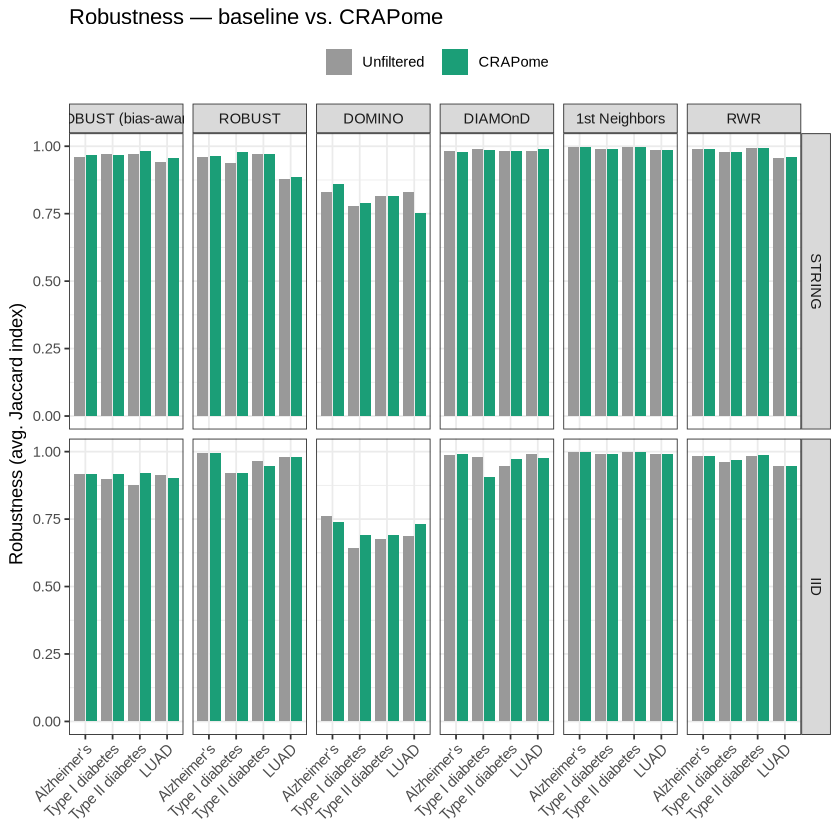

In [4]:
# paired baseline-vs-CRAPome bars, one figure per metric (network rows x method columns)
plot_paired_bars <- function(df, metric, metric_label, title) {
  d <- df %>%
    mutate(disease = fct_disease(disease), network = fct_network(network), amim = fct_amim(amim))
  ggplot(d, aes(x = disease, y = .data[[metric]], fill = config)) +
    geom_col(position = position_dodge2(width = 0.8, padding = 0.1)) +
    facet_grid(network ~ amim) +
    scale_fill_manual(values = CONFIG_COLORS, name = NULL) +
    labs(title = title, x = NULL, y = metric_label) +
    theme_bw() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1), legend.position = "top")
}

# CRAPome - baseline, matched on disease/network/amim
compute_config_delta <- function(df, metric) {
  base <- df %>% filter(!filtered) %>% transmute(disease, network, amim, base = .data[[metric]])
  filt <- df %>% filter(filtered)  %>% transmute(disease, network, amim, val  = .data[[metric]])
  inner_join(filt, base, by = c("disease", "network", "amim")) %>%
    mutate(delta = val - base)
}

plot_delta_heatmap <- function(delta_df, title, fill_label = "Δ (CRAPome − baseline)", scale = 1) {
  d <- delta_df %>%
    mutate(disease = fct_disease(disease), network = fct_network(network),
           amim = fct_amim(amim), delta = delta * scale)
  if (nrow(d) == 0) return(NULL)
  max_abs <- max(abs(d$delta), na.rm = TRUE); if (!is.finite(max_abs) || max_abs == 0) max_abs <- 1
  ggplot(d, aes(x = amim, y = disease, fill = delta)) +
    geom_tile(color = "white") +
    geom_text(aes(label = sprintf("%+.2f", delta)), size = 3) +
    facet_wrap(~ network, ncol = 1) +
    scale_fill_distiller(palette = "RdBu", direction = 1, limits = c(-max_abs, max_abs)) +
    labs(title = title, x = NULL, y = NULL, fill = fill_label) +
    theme_bw() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))
}

for (metric in names(ROB_METRICS)) {
  metric_label <- ROB_METRICS[[metric]]
  # normalized_rediscovery_rate lives in ~[0, 0.02]; x100 keeps the 2-decimal labels legible
  scale <- if (metric == "normalized_rediscovery_rate") 100 else 1

  p_bar <- plot_paired_bars(robustness, metric, metric_label,
                            paste0(metric_label, " — baseline vs. CRAPome"))
  ggsave(file.path(ROBUSTNESS_OUTDIR, paste0(metric, "_bars.png")), p_bar,
         width = 13, height = 5.5, dpi = 300)

  p_heat <- plot_delta_heatmap(
    compute_config_delta(robustness, metric),
    paste0("Δ ", metric_label, " (CRAPome − baseline)"),
    scale = scale
  )
  if (!is.null(p_heat)) {
    ggsave(file.path(ROBUSTNESS_OUTDIR, paste0(metric, "_delta.png")), p_heat,
           width = 8, height = 6, dpi = 300)
  }
}

print(plot_paired_bars(robustness, "avg_jaccard_index", ROB_METRICS[["avg_jaccard_index"]],
                       "Robustness — baseline vs. CRAPome"))

# 2. Module similarity

Two complementary views:

**(a) Paired similarity — how much does CRAPome rewrite each module?** For every
(disease, network, AMIM) the Jaccard similarity between the *baseline* module and the
*CRAPome-filtered* module is computed directly from the published node lists
(`disease_modules/tsv_nodes/<id>.nodes.tsv`). A value near 1 means filtering barely changed the
module; lower values mean the contaminant removal meaningfully reshaped it. Both node scopes are
covered: `whole_module` (all nodes) and `added_nodes_only` (`is_seed == 0` — the non-seed nodes
the AMIM added, dropping any module left empty after seed removal, matching the pipeline's own
no-seeds matrix).

**(b) Overall clustering.** The pipeline's own pooled Jaccard matrix
(`mqc_summaries/jaccard_similarity_matrix_mqc.tsv`) across every module in the run, rendered with
annotation bars for **Disease**, **Network**, **Config** (baseline / CRAPome) and **AMIM** — to
see whether modules cluster by method/disease/network rather than by whether they were filtered
(they should: CRAPome is a light touch).

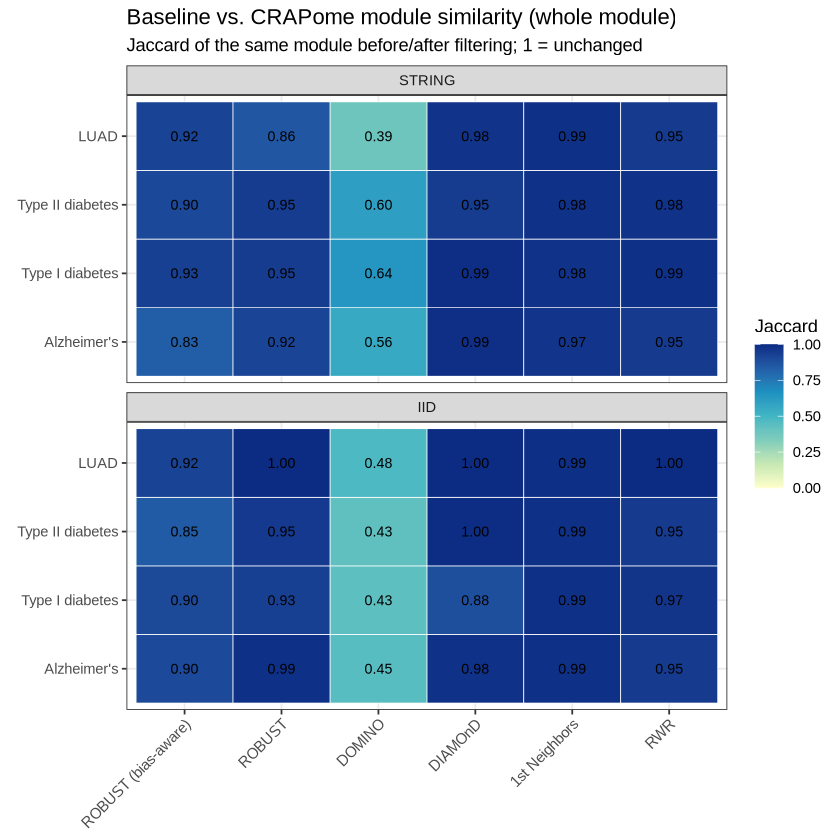

In [5]:
MODULE_SIMILARITY_OUTDIR <- file.path(CRAPOME_OUTDIR, "module_similarity")
dir.create(MODULE_SIMILARITY_OUTDIR, recursive = TRUE, showWarnings = FALSE)

NODE_SCOPES       <- c("whole_module", "added_nodes_only")
NODE_SCOPE_LABELS <- c(whole_module = "whole module", added_nodes_only = "added nodes only")

# node_scope == "added_nodes_only" keeps only non-seed nodes, mirroring module_overlap.py
read_module_gene_set <- function(f, node_scope) {
  df <- read_tsv(f, show_col_types = FALSE,
                 col_types = cols_only(name = col_character(), is_seed = col_double()))
  if (node_scope == "added_nodes_only") df <- df %>% filter(is_seed == 0)
  as.character(df$name)
}

node_files <- list.files(file.path(CRAPOME_RUN, "disease_modules", "tsv_nodes"),
                         pattern = "\\.nodes\\.tsv$", full.names = TRUE)
module_registry <- bind_cols(
  tibble(file = node_files, id = str_remove(basename(node_files), "\\.nodes\\.tsv$")),
  parse_run_id(str_remove(basename(node_files), "\\.nodes\\.tsv$"))
) %>%
  mutate(disease = unname(DISEASE_FROM_SEEDS[seeds_id])) %>%
  filter(!is.na(amim), !is.na(disease))  # drops no_tool network entries

# Jaccard(baseline module, CRAPome module) for each disease/network/amim
paired_similarity <- function(node_scope) {
  reg <- module_registry
  reg$genes <- map(reg$file, read_module_gene_set, node_scope = node_scope)
  reg <- reg %>% filter(lengths(genes) > 0)
  base <- reg %>% filter(!filtered) %>% transmute(disease, network, amim, base_genes = genes)
  filt <- reg %>% filter(filtered)  %>% transmute(disease, network, amim, filt_genes = genes)
  inner_join(filt, base, by = c("disease", "network", "amim")) %>%
    mutate(
      jaccard = map2_dbl(base_genes, filt_genes,
                         ~ length(intersect(.x, .y)) / length(union(.x, .y))),
      node_scope = node_scope
    ) %>%
    select(disease, network, amim, node_scope, jaccard)
}

paired_sim <- map_dfr(NODE_SCOPES, paired_similarity)

plot_paired_similarity <- function(df, node_scope) {
  d <- df %>%
    filter(node_scope == !!node_scope) %>%
    mutate(disease = fct_disease(disease), network = fct_network(network), amim = fct_amim(amim))
  if (nrow(d) == 0) return(NULL)
  ggplot(d, aes(x = amim, y = disease, fill = jaccard)) +
    geom_tile(color = "white") +
    geom_text(aes(label = sprintf("%.2f", jaccard)), size = 3) +
    facet_wrap(~ network, ncol = 1) +
    scale_fill_distiller(palette = "YlGnBu", direction = 1, limits = c(0, 1)) +
    labs(
      title = paste0("Baseline vs. CRAPome module similarity (", NODE_SCOPE_LABELS[node_scope], ")"),
      subtitle = "Jaccard of the same module before/after filtering; 1 = unchanged",
      x = NULL, y = NULL, fill = "Jaccard"
    ) +
    theme_bw() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))
}

for (node_scope in NODE_SCOPES) {
  p <- plot_paired_similarity(paired_sim, node_scope)
  if (is.null(p)) next
  ggsave(file.path(MODULE_SIMILARITY_OUTDIR, paste0("paired_", node_scope, ".png")),
         p, width = 8, height = 6, dpi = 300)
}
print(plot_paired_similarity(paired_sim, "whole_module"))

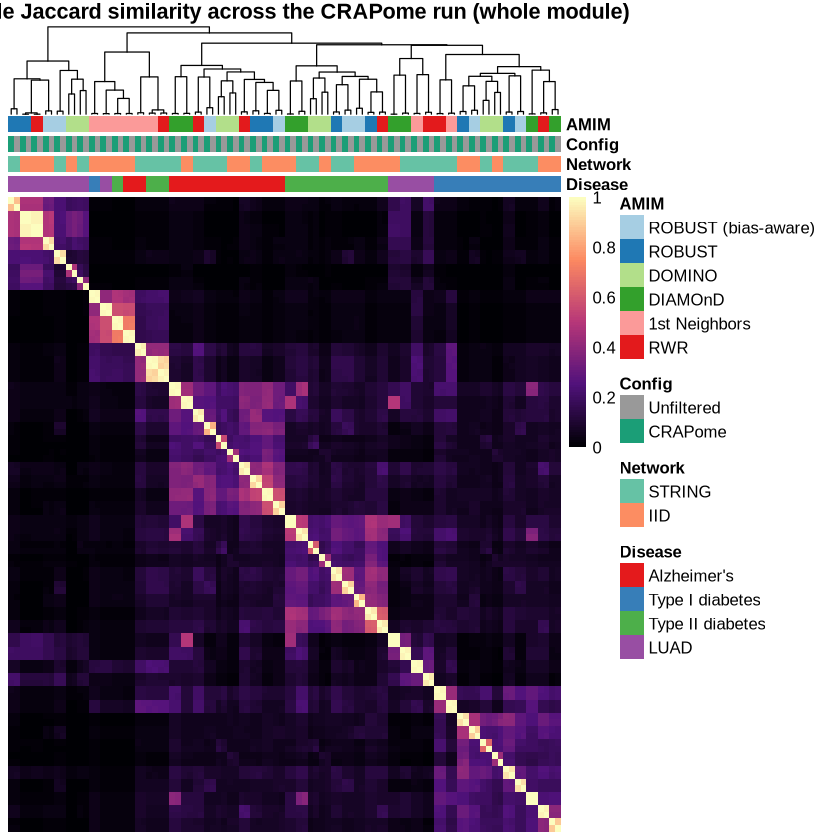

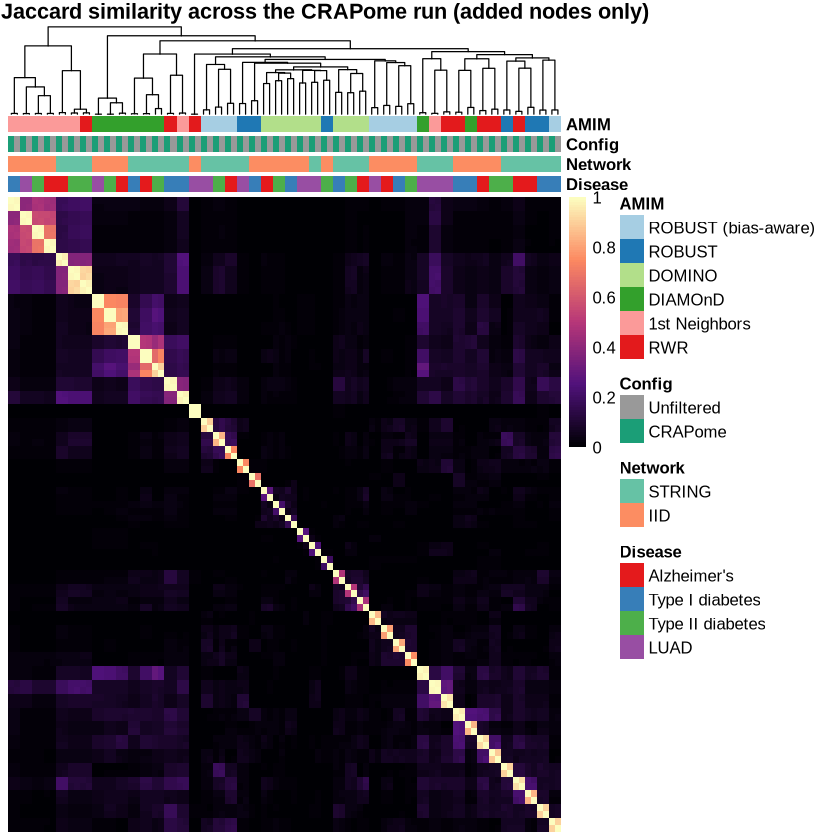

In [6]:
# (b) annotated pooled Jaccard heatmap of every module in the run
JACCARD_MATRIX_FILENAMES <- c(
  whole_module     = "jaccard_similarity_matrix_mqc.tsv",
  added_nodes_only = "jaccard_similarity_no_seeds_matrix_mqc.tsv"
)

read_jaccard_matrix <- function(node_scope) {
  f <- file.path(CRAPOME_RUN, "mqc_summaries", JACCARD_MATRIX_FILENAMES[[node_scope]])
  if (!file.exists(f)) { warning("Missing matrix: ", f); return(NULL) }
  raw <- read_tsv(f, show_col_types = FALSE)
  mat <- as.matrix(raw %>% select(-ID)); rownames(mat) <- raw$ID
  mat
}

save_pheatmap_png <- function(p, filename, width = 10, height = 9, res = 300) {
  png(filename, width = width, height = height, units = "in", res = res)
  grid::grid.newpage(); grid::grid.draw(p$gtable); dev.off()
}

plot_pooled_similarity <- function(node_scope) {
  mat <- read_jaccard_matrix(node_scope)
  if (is.null(mat)) return(NULL)
  meta <- parse_run_id(rownames(mat))
  meta$disease <- unname(DISEASE_FROM_SEEDS[meta$seeds_id])
  keep <- !is.na(meta$amim) & !is.na(meta$disease)  # drop no_tool network rows
  meta <- meta[keep, ]; mat <- mat[keep, keep, drop = FALSE]
  if (nrow(mat) < 2) return(NULL)

  annotation <- data.frame(
    Disease = unname(DISEASE_LABELS[meta$disease]),
    Network = unname(NETWORK_LABELS[meta$network]),
    Config  = if_else(meta$filtered, "CRAPome", "Unfiltered"),
    AMIM    = unname(AMIM_LABELS[meta$amim]),
    row.names = rownames(mat), stringsAsFactors = FALSE
  )
  disease_lvls <- unname(DISEASE_LABELS[DISEASE_ORDER])
  network_lvls <- unname(NETWORK_LABELS[KNOWN_NETWORKS])
  amim_lvls    <- unname(AMIM_LABELS[KNOWN_AMIMS])
  annotation_colors <- list(
    Disease = setNames(brewer.pal(max(3, length(disease_lvls)), "Set1")[seq_along(disease_lvls)], disease_lvls),
    Network = setNames(brewer.pal(max(3, length(network_lvls)), "Set2")[seq_along(network_lvls)], network_lvls),
    Config  = setNames(unname(CONFIG_COLORS[CONFIG_LEVELS]), CONFIG_LEVELS),
    AMIM    = setNames(brewer.pal(max(3, length(amim_lvls)), "Paired")[seq_along(amim_lvls)], amim_lvls)
  )
  pheatmap(
    mat,
    color = colorRampPalette(c("#000004", "#51127c", "#b73779", "#fc8961", "#fcfdbf"))(100),
    breaks = seq(0, 1, length.out = 101),
    annotation_col = annotation, annotation_colors = annotation_colors,
    show_rownames = FALSE, show_colnames = FALSE, treeheight_row = 0, border_color = NA,
    main = paste0("Module Jaccard similarity across the CRAPome run (", NODE_SCOPE_LABELS[node_scope], ")"),
    silent = TRUE
  )
}

for (node_scope in NODE_SCOPES) {
  p <- plot_pooled_similarity(node_scope)
  if (is.null(p)) next
  save_pheatmap_png(p, file.path(MODULE_SIMILARITY_OUTDIR, paste0("pooled_", node_scope, ".png")))
  grid::grid.newpage(); grid::grid.draw(p$gtable)
}

# 3. Biological relevance (g:Profiler overrepresentation)

Reads `evaluation/gprofiler/<module_id>/<module_id>.gprofiler2.all_enriched_pathways.tsv` per
module. g:Profiler was run significant-only, so a pathway absent from a module's file is treated
as `-log10(p) = 0` (p = 1) throughout — aggressive filtering that drops a pathway entirely is not
flattered by averaging over only the survivors.

Two analyses, mirroring the expression notebook:

1. **Pathway correspondence to baseline** (whole module): mean `-log10(p)`, evaluated in the
   CRAPome module, of the pathways that were significant in the *unfiltered baseline* module —
   i.e. does filtering preserve the baseline's enrichment signal? Shown against the baseline's own
   self-score.
2. **Disease-specific pathway significance** (both node scopes): the `-log10(p)` of each disease's
   directly-naming KEGG pathway (e.g. KEGG "Alzheimer disease"), baseline vs. CRAPome.

In [7]:
GPROFILER_OUTDIR <- file.path(CRAPOME_OUTDIR, "gprofiler")
dir.create(GPROFILER_OUTDIR, recursive = TRUE, showWarnings = FALSE)

read_significant_terms <- function(dir_name) {
  f <- file.path(CRAPOME_RUN, "evaluation", "gprofiler", dir_name,
                 paste0(dir_name, ".gprofiler2.all_enriched_pathways.tsv"))
  empty <- tibble(term_id = character(0), p_value = numeric(0), precision = numeric(0))
  if (!file.exists(f) || file.size(f) == 0) return(empty)  # 0-byte = nothing significant
  out <- read_tsv(f, show_col_types = FALSE,
                  col_types = cols_only(term_id = col_character(), p_value = col_double(),
                                        precision = col_double()))
  if (!all(c("term_id", "p_value", "precision") %in% names(out))) return(empty)
  out
}

gp_dirs <- list.dirs(file.path(CRAPOME_RUN, "evaluation", "gprofiler"),
                     recursive = FALSE, full.names = FALSE)
is_added <- str_ends(gp_dirs, "\\.added_nodes_only")
base_id  <- if_else(is_added, str_remove(gp_dirs, "\\.added_nodes_only$"), gp_dirs)

gprofiler_all <- parse_run_id(base_id) %>%
  mutate(
    dir_name   = gp_dirs,
    node_scope = if_else(is_added, "added_nodes_only", "whole_module"),
    disease    = unname(DISEASE_FROM_SEEDS[seeds_id]),
    threshold  = as.numeric(threshold)
  ) %>%
  filter(!is.na(amim), !is.na(disease))

gprofiler_all$terms <- map(gprofiler_all$dir_name, read_significant_terms)
dplyr::count(gprofiler_all, disease, node_scope, config = if_else(filtered, "CRAPome", "Unfiltered"))

disease,node_scope,config,n
<chr>,<chr>,<chr>,<int>
LUAD,added_nodes_only,CRAPome,12
LUAD,added_nodes_only,Unfiltered,12
LUAD,whole_module,CRAPome,12
LUAD,whole_module,Unfiltered,12
alzheimers,added_nodes_only,CRAPome,12
alzheimers,added_nodes_only,Unfiltered,12
alzheimers,whole_module,CRAPome,12
alzheimers,whole_module,Unfiltered,12
diabetes_typeI,added_nodes_only,CRAPome,12


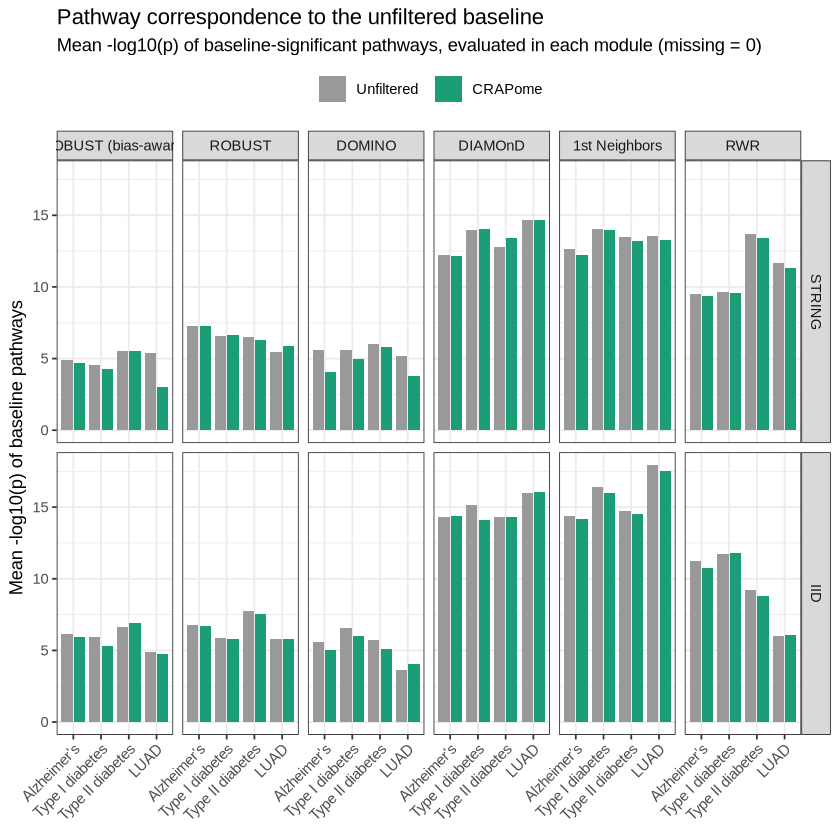

In [8]:
# 1. pathway correspondence to the unfiltered baseline (whole module only)
gprofiler_modules <- gprofiler_all %>% filter(node_scope == "whole_module")

# mean -log10(p) of the baseline's significant term_ids, evaluated in a filtered module
# (missing term_id -> -log10(p) = 0, i.e. p = 1)
score_against_baseline <- function(filtered_terms, baseline_term_ids) {
  if (length(baseline_term_ids) == 0) return(NA_real_)
  p <- setNames(filtered_terms$p_value, filtered_terms$term_id)[baseline_term_ids]
  v <- -log10(pmax(p, 1e-300)); v[is.na(v)] <- 0; mean(v)
}

baseline_lookup <- gprofiler_modules %>%
  filter(!filtered) %>%
  transmute(disease, network, amim, baseline_term_ids = map(terms, "term_id"))

corr_filtered <- gprofiler_modules %>%
  filter(filtered) %>%
  left_join(baseline_lookup, by = c("disease", "network", "amim")) %>%
  mutate(score = map2_dbl(terms, baseline_term_ids, score_against_baseline),
         config = "CRAPome") %>%
  select(disease, network, amim, config, score)

# baseline self-score: mean -log10(p) of its own significant pathways
corr_baseline <- gprofiler_modules %>%
  filter(!filtered) %>%
  mutate(score = map_dbl(terms, ~ if (nrow(.x) == 0) NA_real_ else mean(-log10(pmax(.x$p_value, 1e-300)))),
         config = "Unfiltered") %>%
  select(disease, network, amim, config, score)

corr_all <- bind_rows(corr_baseline, corr_filtered) %>%
  mutate(config = factor(config, levels = CONFIG_LEVELS))

p_corr <- corr_all %>%
  mutate(disease = fct_disease(disease), network = fct_network(network), amim = fct_amim(amim)) %>%
  ggplot(aes(x = disease, y = score, fill = config)) +
  geom_col(position = position_dodge2(width = 0.8, padding = 0.1)) +
  facet_grid(network ~ amim) +
  scale_fill_manual(values = CONFIG_COLORS, name = NULL) +
  labs(
    title = "Pathway correspondence to the unfiltered baseline",
    subtitle = "Mean -log10(p) of baseline-significant pathways, evaluated in each module (missing = 0)",
    x = NULL, y = "Mean -log10(p) of baseline pathways"
  ) +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1), legend.position = "top")

ggsave(file.path(GPROFILER_OUTDIR, "baseline_correspondence.png"), p_corr,
       width = 13, height = 5.5, dpi = 300)
print(p_corr)

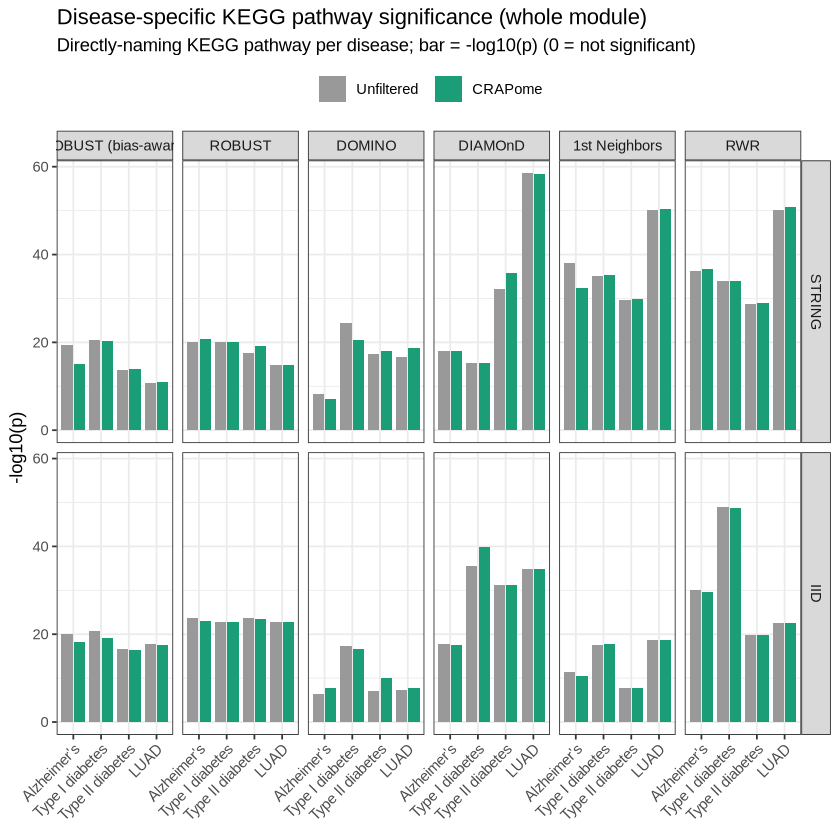

In [9]:
# 2. disease-specific pathway significance, baseline vs. CRAPome (both node scopes)
# each disease's directly-naming KEGG pathway (one per disease -> clean x = disease bars)
DIRECT_DISEASE_PATHWAYS <- c(
  alzheimers      = "KEGG:05010",  # Alzheimer disease
  diabetes_typeI  = "KEGG:04940",  # Type I diabetes mellitus
  diabetes_typeII = "KEGG:04930",  # Type II diabetes mellitus
  LUAD            = "KEGG:05223"   # Non-small cell lung cancer
)

lookup_score <- function(terms, term_id) {
  if (!"term_id" %in% names(terms)) return(0)
  p <- terms$p_value[match(term_id, terms$term_id)]
  if (length(p) != 1 || is.na(p)) 0 else -log10(pmax(p, 1e-300))  # not significant -> p = 1
}

disease_pathway_scores <- gprofiler_all %>%
  mutate(
    pathway_id = unname(DIRECT_DISEASE_PATHWAYS[disease]),
    score      = map2_dbl(terms, pathway_id, lookup_score),
    config     = factor(if_else(filtered, "CRAPome", "Unfiltered"), levels = CONFIG_LEVELS)
  )

DISEASE_PATHWAYS_OUTDIR <- file.path(GPROFILER_OUTDIR, "disease_pathways")
dir.create(DISEASE_PATHWAYS_OUTDIR, recursive = TRUE, showWarnings = FALSE)

plot_disease_pathways <- function(node_scope) {
  d <- disease_pathway_scores %>%
    filter(node_scope == !!node_scope) %>%
    mutate(disease = fct_disease(disease), network = fct_network(network), amim = fct_amim(amim))
  if (nrow(d) == 0) return(NULL)
  ggplot(d, aes(x = disease, y = score, fill = config)) +
    geom_col(position = position_dodge2(width = 0.8, padding = 0.1)) +
    facet_grid(network ~ amim) +
    scale_fill_manual(values = CONFIG_COLORS, name = NULL) +
    labs(
      title = paste0("Disease-specific KEGG pathway significance (", NODE_SCOPE_LABELS[node_scope], ")"),
      subtitle = "Directly-naming KEGG pathway per disease; bar = -log10(p) (0 = not significant)",
      x = NULL, y = "-log10(p)"
    ) +
    theme_bw() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1), legend.position = "top")
}

for (node_scope in NODE_SCOPES) {
  p <- plot_disease_pathways(node_scope)
  if (is.null(p)) next
  ggsave(file.path(DISEASE_PATHWAYS_OUTDIR, paste0(node_scope, ".png")), p,
         width = 13, height = 5.5, dpi = 300)
}
print(plot_disease_pathways("whole_module"))

# Method-wise summary (one figure)

A single figure summarising the whole run per AMIM: **methods are the columns**, the robustness
measures (avg. Jaccard, seed rediscovery, normalized rediscovery) and the disease-specific KEGG
pathway significance are the **rows**. Within each cell the diseases are grouped on the x-axis, and
each disease shows its **unfiltered bar (grey) directly next to its CRAPome bar (coloured by
disease)** — so the baseline→filtered change is read as the grey→colour pair. Values are the mean
across both base networks; the y-axis is free per metric row. Disease codes: AD = Alzheimer's,
T1D/T2D = Type I/II diabetes, LUAD. Output: `results_analysis_output/crapome/method_summary.png`.

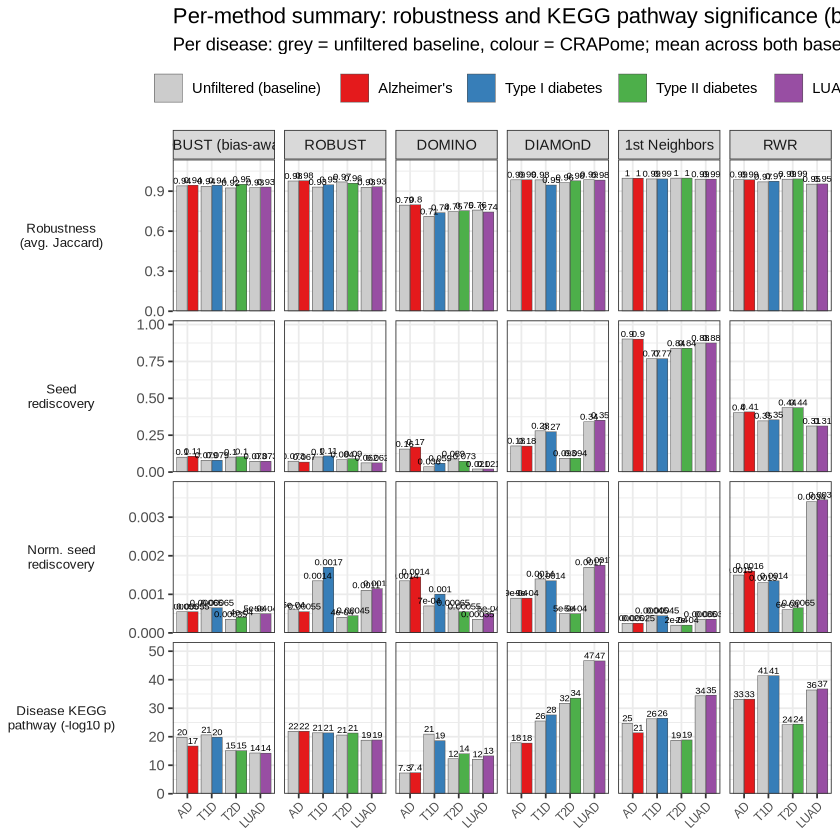

In [10]:
# reuses robustness and disease_pathway_scores from the sections above
DISEASE_COLORS <- setNames(
  brewer.pal(max(3, length(DISEASE_ORDER)), "Set1")[seq_along(DISEASE_ORDER)],
  DISEASE_ORDER
)
DISEASE_SHORT <- c(alzheimers = "AD", diabetes_typeI = "T1D",
                   diabetes_typeII = "T2D", LUAD = "LUAD")

# short, wrapped metric-row labels so the left strip takes less horizontal space
ROB_METRICS_SHORT <- c(
  avg_jaccard_index           = "Robustness\n(avg. Jaccard)",
  rediscovery_rate            = "Seed\nrediscovery",
  normalized_rediscovery_rate = "Norm. seed\nrediscovery"
)
DISEASE_PATHWAY_LABEL <- "Disease KEGG\npathway (-log10 p)"

rob_summary <- robustness %>%
  pivot_longer(all_of(names(ROB_METRICS)), names_to = "metric", values_to = "value") %>%
  group_by(disease, amim, config, metric) %>%
  summarise(value = mean(value, na.rm = TRUE), .groups = "drop") %>%
  mutate(metric_label = unname(ROB_METRICS_SHORT[metric]))

path_disease_summary <- disease_pathway_scores %>%
  filter(node_scope == "whole_module") %>%
  group_by(disease, amim, config) %>%
  summarise(value = mean(score, na.rm = TRUE), .groups = "drop") %>%
  mutate(metric = "disease_pathway", metric_label = DISEASE_PATHWAY_LABEL)

metric_levels <- c(
  unname(ROB_METRICS_SHORT[c("avg_jaccard_index", "rediscovery_rate", "normalized_rediscovery_rate")]),
  DISEASE_PATHWAY_LABEL
)

summary_all <- bind_rows(rob_summary, path_disease_summary) %>%
  mutate(
    amim         = fct_amim(amim),
    disease      = factor(disease, levels = DISEASE_ORDER),
    metric_label = factor(metric_label, levels = metric_levels),
    config       = factor(config, levels = CONFIG_LEVELS),
    # unfiltered -> grey; CRAPome -> the disease's colour, so each disease's grey/colour
    # pair sits together on the x-axis
    fill_grp     = factor(if_else(config == "Unfiltered", "Unfiltered", as.character(disease)),
                          levels = c("Unfiltered", DISEASE_ORDER))
  )

fill_values <- c(Unfiltered = "grey80", DISEASE_COLORS)
fill_labels <- c(Unfiltered = "Unfiltered (baseline)", DISEASE_LABELS)

# x = disease; group = config dodges the unfiltered/CRAPome bars next to each other per disease
p_summary <- ggplot(summary_all, aes(x = disease, y = value, group = config, fill = fill_grp)) +
  geom_col(position = position_dodge2(width = 0.9, padding = 0.05), width = 0.9,
           color = "grey30", linewidth = 0.15) +
  geom_text(aes(label = signif(value, 2)),
            position = position_dodge2(width = 0.9, padding = 0.05),
            vjust = -0.35, size = 2) +
  facet_grid(metric_label ~ amim, scales = "free_y", switch = "y") +
  scale_x_discrete(labels = DISEASE_SHORT[DISEASE_ORDER]) +
  scale_fill_manual(values = fill_values, labels = fill_labels, name = NULL) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.14))) +
  labs(
    title = "Per-method summary: robustness and KEGG pathway significance (baseline vs. CRAPome)",
    subtitle = "Per disease: grey = unfiltered baseline, colour = CRAPome; mean across both base networks; y free per row",
    x = NULL, y = NULL
  ) +
  theme_bw() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1, size = 7),
    strip.placement = "outside", strip.background.y = element_blank(),
    strip.text.y.left = element_text(angle = 0, size = 8, margin = margin(r = 2)),
    legend.position = "top", plot.margin = margin(5, 5, 5, 2)
  )

ggsave(file.path(CRAPOME_OUTDIR, "method_summary.png"), p_summary, width = 20, height = 9, dpi = 300)
print(p_summary)